# 5115056023 HW2：洪水機率多元線性回歸

CRISP-DM。資料來源與限制見 README.md；完整 GPT 對話仍待本人匯出。此 Notebook 呼叫與主程式相同的實驗入口，避免維護兩份不同邏輯。

## Business / Data Understanding
Kaggle 50,000 筆，20 個輸入；目標實際為浮點數。原始外部來源不明，近似固定線性生成公式，不代表真實洪水資料。

In [1]:
from pathlib import Path
import pandas as pd, json
ROOT=Path.cwd()
assert (ROOT/'5115056023_hw2.py').is_file(), '請在作業資料夾執行'
df=pd.read_csv(ROOT/'data/flood.csv')
print(df.shape)
df.head()

(50000, 21)


,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,Encroachments,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,3,8,6,6,4,4,6,2,3,2,...,10,7,4,2,3,4,3,2,6,0.450
1,8,4,5,7,7,9,1,5,5,4,...,9,2,6,2,1,1,9,1,3,0.475
2,3,10,4,1,7,5,4,7,4,9,...,7,4,4,8,6,1,8,3,6,0.515
3,4,4,2,7,3,4,1,4,6,4,...,4,2,6,6,8,8,6,6,10,0.520
4,3,7,5,2,5,8,5,2,7,5,...,7,6,5,3,3,4,4,3,4,0.475


## Preparation / Modeling
先切分 60/20/20；五折 CV 與選特徵完全限於開發資料；校準集只建區間。執行下格會重跑全部實驗。

In [2]:
import runpy
runpy.run_path(str(ROOT/'5115056023_hw2.py'),run_name='__main__')

Mean baseline: CV MSE=0.002518681


OLS full: CV MSE=0.000000000


Ridge alpha=0.01: CV MSE=0.000000000


Ridge alpha=0.1: CV MSE=0.000000000


Ridge alpha=1: CV MSE=0.000000000


...

Permutation k=20: CV MSE=0.000000000


Histogram gradient boosting (comparison): CV MSE=0.000217179


Locked selected linear model: OLS full


{
  "student_id": "5115056023",
  "date": "2026-10-16",
  "seed": 42,
  "source": {
    "title": "Flood Prediction Dataset",
    "ref": "kamrulhasan0077/flood-prediction-dataset",
    "version": 1,
    "url": "https://www.kaggle.com/datasets/kamrulhasan0077/flood-prediction-dataset",
    "license": "CC0: Public Domain",
    "download_url": "https://www.kaggle.com/api/v1/datasets/download/kamrulhasan0077/flood-prediction-dataset?datasetVersionNumber=1",
    "retrieved": "2026-10-16",
    "sha256": "9cf6a2339d7c7524620f99497801c278e3c1ed0aca8d0fde22a683508fa10e8d",
    "rows": 50000,
    "columns": [
      "MonsoonIntensity",
      "TopographyDrainage",
      "RiverManagement",
      "Deforestation",
      "Urbanization",
      "ClimateChange",
      "DamsQuality",
      "Siltation",
      "AgriculturalPractices",
      "Encroachments",
      "IneffectiveDisasterPreparedness",
      "DrainageSystems",
      "CoastalVulnerability",
      "Landslides",
      "Watersheds",
      "Deteriorat

{'__name__': '__main__',
 '__doc__': '5115056023 HW2: CRISP-DM + linear regression + feature selection.\nRun: python 5115056023_hw2.py\nEvidence integration/report: python build_report.py ; python package_submission.py\n',
 '__package__': '',
 '__loader__': None,
 '__spec__': None,
 '__file__': 'C:\\Users\\a8017\\Desktop\\1014doc\\hw2_flood\\5115056023_hw2.py',
 '__cached__': None,
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-in'\nidentifiers of Python; for example, builtins.len is\nthe full name for the built-in function len().\n\nThis module is not normally accessed explicitly by most\napplications, but can be useful in modules that provide\nobjects with the same name as a built-in value, but in\nwhich the built-in of that name is also needed.",
  '__package__': '',
  '__loader__': _frozen_importlib.BuiltinImporter,
  '__spec__': ModuleSpec(name='builtins', loader=

## Evaluation
依 CV 排名，不能以 Test 分數重新選模型。

In [3]:
pd.read_csv(ROOT/'outputs/test_metrics.csv').head(20)

,scheme,k,MAE,MSE,RMSE,R2,Adjusted_R2,outside_0_1,rank,CV_MSE,CV_RMSE
0,Forward SFS k=20,20,1.635192e-16,4.320462e-32,2.078572e-16,1.000000,1.000000,0,1,1.013367e-31,3.183342e-16
1,Lasso selection k=20,20,1.635192e-16,4.320462e-32,2.078572e-16,1.000000,1.000000,0,2,1.013367e-31,3.183342e-16
2,OLS full,20,1.635192e-16,4.320462e-32,2.078572e-16,1.000000,1.000000,0,3,1.013367e-31,3.183342e-16
3,Permutation k=20,20,1.635192e-16,4.320462e-32,2.078572e-16,1.000000,1.000000,0,4,1.013367e-31,3.183342e-16
4,RFE k=20,20,1.635192e-16,4.320462e-32,2.078572e-16,1.000000,1.000000,0,5,1.013367e-31,3.183342e-16
5,SelectKBest k=20,20,1.635192e-16,4.320462e-32,2.078572e-16,1.000000,1.000000,0,6,1.013367e-31,3.183342e-16
6,Ridge alpha=0.01,20,1.318285e-08,2.728041e-16,1.651678e-08,1.000000,1.000000,0,7,4.309870e-16,2.076023e-08
7,Ridge alpha=0.1,20,1.318281e-07,2.728025e-14,1.651673e-07,1.000000,1.000000,0,8,4.309838e-14,2.076015e-07
8,Ridge alpha=1,20,1.318242e-06,2.727862e-12,1.651624e-06,1.000000,1.000000,0,9,4.309517e-12,2.075938e-06
9,Lasso alpha=1e-06,20,3.539991e-06,1.967106e-11,4.435207e-06,1.000000,1.000000,0,10,1.988855e-11,4.459658e-06


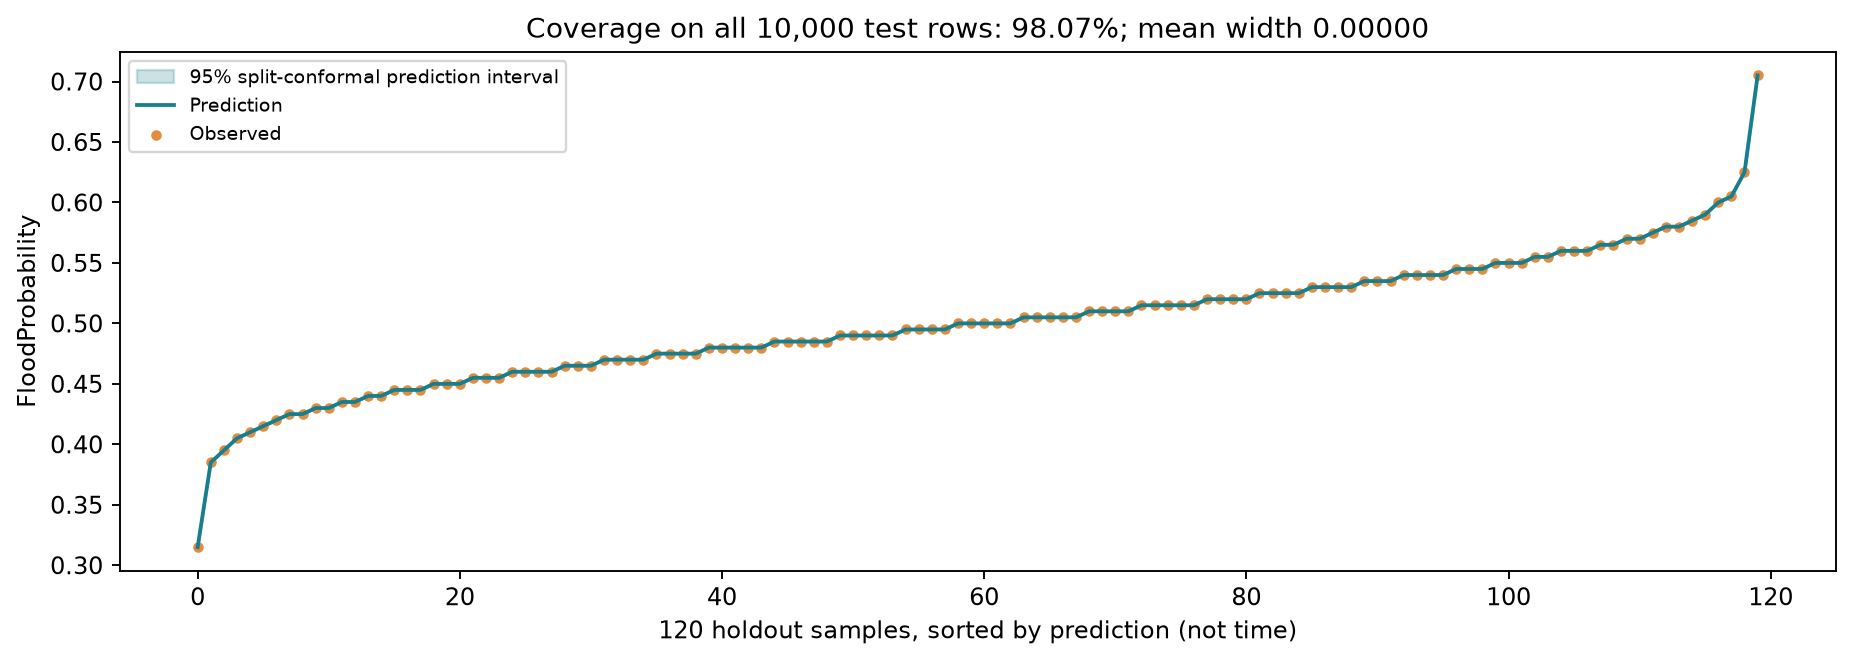

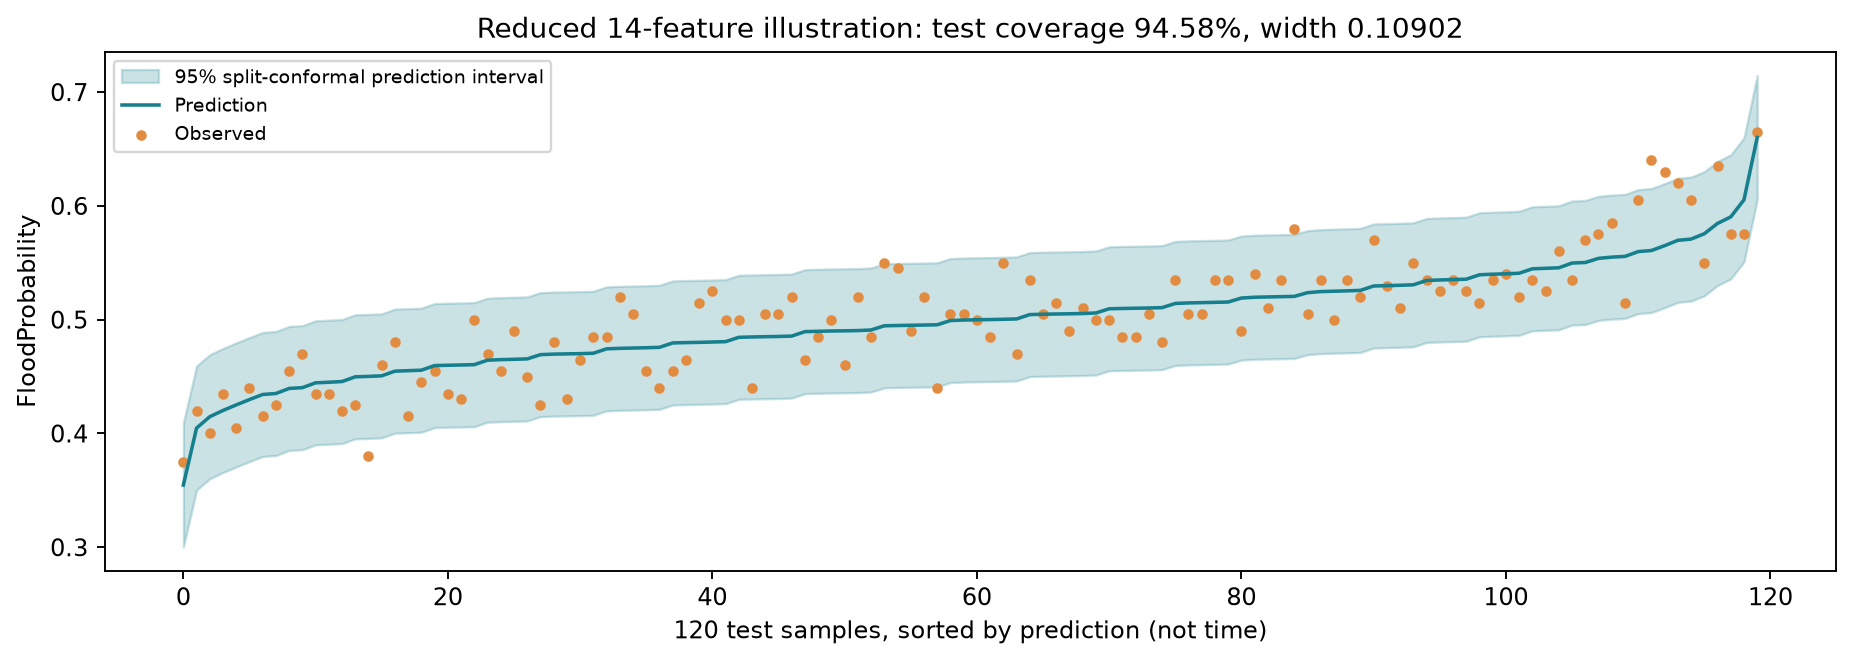

In [4]:
from IPython.display import display, Image
display(Image(filename=str(ROOT/'outputs/figures/05_prediction_intervals.png')))
display(Image(filename=str(ROOT/'outputs/figures/09_reduced_prediction_intervals.png')))

## Deployment / AI 證據
web/index.html 可離線開啟。用 predict_sample.py 載入同一模型與校準區間。報告製作執行 build_report.py；對話 PDF 匯出後再合併。

In [5]:
print((ROOT/'evidence/notebooklm_summary.txt').read_text(encoding='utf-8-sig'))

NotebookLM 研究摘要（學生於 2026-10-16 貼回回答，經 GPT 核對與編修）

本研究依 NotebookLM 對 Kaggle Flood Prediction Dataset、scikit-learn 特徵選擇文件，以及 conformal prediction 論文的整理，使用 20 個環境與社會因素分數建立多元線性回歸，預測連續目標 FloodProbability [1][4][5]。特徵選擇可降低模型複雜度、減少無關欄位，但不保證提升準確度；應在訓練資料內比較 SelectKBest、RFE、SFS、Lasso 與 permutation importance，再由交叉驗證決定方案 [4]。此資料下載版本有 50,000 筆，輸入特徵為整數，而目標是浮點數，不能沿用來源頁「全部 int64」的誤述。95% split-conformal 預測區間利用獨立校準集的絕對殘差分位數建立，在資料交換性假設下提供有限樣本的邊際涵蓋率，並非每個固定地區或特定輸入都具有 95% 條件保證 [5]。資料上傳者承認原始出處、蒐集方法與地理覆蓋不明，故結果僅適合教學研究，不應直接用於實際防災 [1]。

GPT 核對與編修：修正目標 dtype、特徵選擇不必然改善表現，以及交換性與邊際涵蓋率的限制。上文引用編號對應報告參考來源。學生貼回的來源名稱共有三項，但未附 NotebookLM 可點選的引用標記或筆記本連結；本報告不宣稱已獨立查驗 NotebookLM 帳戶或筆記本。

